# Анализ результатов A/B теста новой платёжной воронки

### Цели и задачи проекта

**Цель** - изучить результаты А/В теста крупного интернет - магазина Азии и определить влияние новой платёжной воронки на конверсию в покупку. 

**Задачи проекта**:
- Выполнить предобработку данных, 
- Проверить, верно ли разделены пользователи на группы, 
- Построить графики кумулятивной динамики метрик,
- Провести статистический тест для проверки гипотезы, 
- Сформулировать выводы и рекомендации. 

### Описание данных 

Данные состоят из 4 датасетов: 

- `new_users_test_2025.csv` — данные всех пользователей, зарегистрировавшихся в интернет-магазине с 1 по 14 июня 2025 года. 
    - `user_id` — уникальный идентификатор пользователя;
    - `first_date` — дата регистрации;
    - `region` — регион, к которому относится пользователь;
    - `device` — устройство, с которого происходила регистрация.
    
- `sessions_test_2025.csv` — данные всех сессий новых пользователей с 1 по 21 июня 2025 года. 
    - `user_id` — уникальный идентификатор пользователя;
    - `session_start` — дата начала сессии;
    - `session_duration` — длительность сессии в минутах.
    
- `purchases_test_2025.csv` — данные всех покупок новых пользователей с 1 по 21 июня 2025 года.
    - `user_id` — уникальный идентификатор пользователя;
    - `event_dt` — дата и время покупки;
    - `revenue` — стоимость покупки в долларах.
    
- `participants_test_2025.csv` — данные участников тестов. Скачать файл.
    - `user_id` — уникальный идентификатор пользователя;
    - `group` — группа А/B-теста;
    - `ab_test` — название А/B-теста.

### Структура проекта

1. Загрузка и подготовка данных
2. Исследовательский анализ данных теста
3. Проверка Гипотез
4. Формулирование выводов и рекомендаций

## 1. Загрузка и подготовка данных

In [1]:
#Импортируем библиотеки
import pandas as pd
import numpy as np

#Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

#Загружаем z-test пропорций
from statsmodels.stats.proportion import proportions_ztest

In [2]:
# Выгружаем данные в переменные
new_users_test = pd.read_csv('/Users/annazakharova/Downloads/new_users_test_2025.csv')
sessions_test = pd.read_csv('/Users/annazakharova/Downloads/sessions_test_2025.csv')
purchases_test = pd.read_csv('/Users/annazakharova/Downloads/purchases_test_2025.csv')
participants_test = pd.read_csv('/Users/annazakharova/Downloads/participants_test_2025.csv')

In [3]:
#Выведем первые 5 строк каждого датафрейма и познакомимся с содержанием таблиц:
display(new_users_test.head())
display(sessions_test.head())
display(purchases_test.head())
display(participants_test.head())

,user_id,first_date,region,device
0,D72A72121175D8BE,2025-06-01,South Asia,iPhone
1,F1C668619DFE6E65,2025-06-01,Southeast Asia,iPhone
2,2E1BF1D4C37EA01F,2025-06-01,Central Asia,Mac
3,50734A22C0C63768,2025-06-01,Central Asia,Android
4,E1BDDCE0DAFA2679,2025-06-01,Southeast Asia,iPhone


,user_id,session_start,session_duration
0,D72A72121175D8BE,2025-06-01 05:51:20,1.0
1,F1C668619DFE6E65,2025-06-01 15:28:14,5.0
2,2E1BF1D4C37EA01F,2025-06-01 16:19:36,3.0
3,50734A22C0C63768,2025-06-01 21:06:51,1.0
4,E1BDDCE0DAFA2679,2025-06-01 10:03:00,2.0


,user_id,event_dt,revenue
0,50734A22C0C63768,2025-06-01 21:06:51,4.99
1,0FC21E6F8FAA8DEC,2025-06-01 06:36:08,4.99
2,9CD9F34546DF254C,2025-06-01 14:40:29,99.99
3,1FD7660FDF94CA1F,2025-06-01 04:53:00,4.99
4,E6AF85675078215D,2025-06-01 11:40:09,4.99


,user_id,group,ab_test
0,6A8825D752FCFFB6,A,new_payment_funnel_test_summer_2025
1,0B75608CBBA59791,B,new_payment_funnel_test_summer_2025
2,6B9D2F7685B83C73,A,new_payment_funnel_test_summer_2025
3,6435D4C2E66A7F75,B,new_payment_funnel_test_summer_2025
4,4F815438BBD2BB7E,A,new_payment_funnel_test_summer_2025


In [4]:
#Изучим информацию в датасетах 
new_users_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131486 entries, 0 to 131485
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   user_id     131486 non-null  object
 1   first_date  131486 non-null  object
 2   region      131486 non-null  object
 3   device      131486 non-null  object
dtypes: object(4)
memory usage: 4.0+ MB


In [5]:
sessions_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 491443 entries, 0 to 491442
Data columns (total 3 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   user_id           491443 non-null  object 
 1   session_start     491443 non-null  object 
 2   session_duration  491443 non-null  float64
dtypes: float64(1), object(2)
memory usage: 11.2+ MB


In [6]:
purchases_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149152 entries, 0 to 149151
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   user_id   149152 non-null  object 
 1   event_dt  149152 non-null  object 
 2   revenue   149152 non-null  float64
dtypes: float64(1), object(2)
memory usage: 3.4+ MB


In [7]:
participants_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3291 entries, 0 to 3290
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  3291 non-null   object
 1   group    3291 non-null   object
 2   ab_test  3291 non-null   object
dtypes: object(3)
memory usage: 77.3+ KB


Мы видим, что во всех датасетах данные полные, пропусков в них нет, однако столбцы с датами во всех таблицах имеют тип `object`. Поэтому преобразуем их в тип даты и времени для дальнейшей работы с ними. 

In [8]:
new_users_test['first_date'] = pd.to_datetime(new_users_test['first_date']).dt.date
sessions_test['session_start'] = pd.to_datetime(sessions_test['session_start']).dt.date
purchases_test['event_dt'] = pd.to_datetime(purchases_test['event_dt']).dt.date

In [9]:
#Рассмотрим, участники каких тестов попали в датасет
participants_test['ab_test'].unique()

array(['new_payment_funnel_test_summer_2025', 'new_login_screen_apac'],
      dtype=object)

Так как мы анализируем тест `new_payment_funnel_test_summer_2025`, удалим данные участников из другого теста

In [10]:
participants_test = participants_test[participants_test['ab_test'] == 'new_payment_funnel_test_summer_2025']

Таким образом, данные готовы к дальнейшей работе. 
___

Теперь убедимся, что пользователи разделены правильным образом, и необходимые метрики корректно считаются. 

In [11]:
#Рассчитаем количество уникальных пользователей в каждой из экспериментальных групп
count_a = participants_test[participants_test['group'] == 'A']['user_id'].nunique()
count_b = participants_test[participants_test['group'] == 'B']['user_id'].nunique()
print(f'Количество уникальных пользователей в группе А - {count_a} человек.')
print(f'Количество уникальных пользователей в группе В - {count_b} человек.')

Количество уникальных пользователей в группе А - 1598 человек.
Количество уникальных пользователей в группе В - 1468 человек.


In [12]:
# Рассчитаем процентное отклонение между группами 
P = 100 * abs(count_a - count_b) / count_a
print(f"Процентное отклонение: {P:.2f}%")

Процентное отклонение: 8.14%


Кажется, что процентное отклонение достаточно большое, однако, посмотрим на долю в каждой группе от общего числа пользователей: 

In [13]:
share_a = 100 * count_a / (count_a + count_b)
share_b = 100 * count_b / (count_a + count_b)
print(f"Доля группы А составляет {share_a:.2f}%")
print(f"Доля группы B составляет {share_b:.2f}%")

Доля группы А составляет 52.12%
Доля группы B составляет 47.88%


Таким образом, мы видим, что распределение отклоняется от 50% примерно на 2.1%, поэтому можем продолжить анализ. 

Проверим, что никто из пользователей обеих групп случайно не попал в обе группы одновременно: 

In [14]:
# Исследуем пересечение пользователей в группах А и В 
# Посчитаем количество уникальных групп на каждого пользователя
participants_test.groupby('user_id')['group'].nunique().sort_values(ascending = False)

user_id
002057F7D795A6D5    1
AD8F832B1A4C76DD    1
AD15DE189CD5F61A    1
AD1D0074F91AC587    1
AD1E9253F7D06A28    1
                   ..
590B7B27E78FC2A2    1
592D185DE0C113D5    1
5930DF8E6DFE7577    1
5936628883D6B68F    1
FFF227AB742E5C75    1
Name: group, Length: 3066, dtype: int64

Мы видим, что группы независимы, никто из пользоватеей не попал в обе группы одновременно, можем продолжать наш анализ. 

Теперь убедимся, что пользователи равномерно распределены по категориальным переменным: региону и типу устройства. 

Для начала объединим данные из датасета `new_users_test_2025.csv` со всеми новыми пользователями с 1 по 14 июня. С данными из датасета `participants_test`, где содержится принадлежность пользователей к контрольной и тестовой группам. 

In [15]:
# Объединим данные из датасета с новыми пользователями и разделением их на группы
new_participants_test = new_users_test.merge(participants_test, on = 'user_id')

In [16]:
# Рассмотрим равномерность распределения пользователей по устройствам (группа А)
type_device_a = round(new_participants_test[new_participants_test['group']== 'A'].groupby('device')['user_id'].nunique()/
                      new_participants_test[new_participants_test['group']== 'A']['user_id'].nunique(),4)
type_device_a

device
Android    0.4487
Mac        0.0845
PC         0.2647
iPhone     0.2021
Name: user_id, dtype: float64

In [17]:
# Рассмотрим равномерность распределения пользователей по устройствам (группа B)
type_device_b = round(new_participants_test[new_participants_test['group']== 'B'].groupby('device')['user_id'].nunique()/
                      new_participants_test[new_participants_test['group']== 'B']['user_id'].nunique(),4)
type_device_b

device
Android    0.4373
Mac        0.1117
PC         0.2527
iPhone     0.1982
Name: user_id, dtype: float64

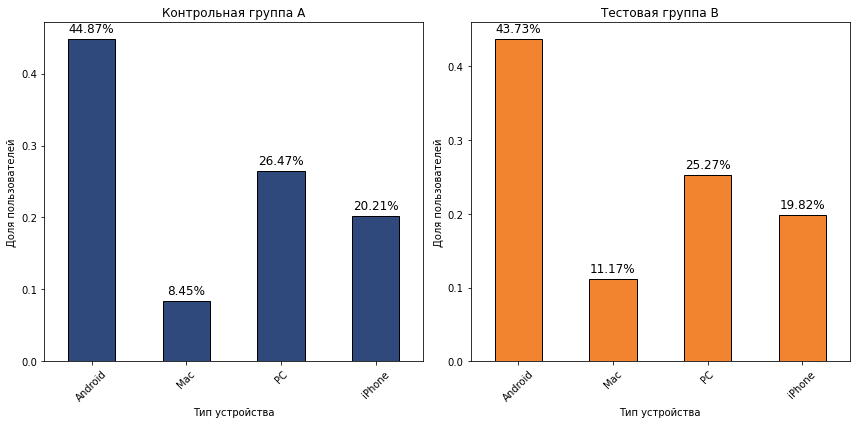

In [18]:
# Построим диаграммы с долей пользователей по типам устройств в обеих группах

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))  

type_device_a.plot(
    kind = 'bar',
    rot = 45,
    legend = False,
    color = '#30497D',
    edgecolor = 'k',
    ax = ax1
)

for p in ax1.patches:
    height = p.get_height()
    ax1.text(
        p.get_x() + p.get_width() / 2., 
        height + 0.005, 
        f'{height:.2%}',  
        ha='center',      
        va='bottom',       
        fontsize=12
    )

ax1.set_xlabel('Тип устройства')
ax1.set_ylabel('Доля пользователей')
ax1.set_title('Контрольная группа А')

type_device_b.plot(
    kind = 'bar',
    rot = 45,
    legend = False,
    color = '#F2842F',
    edgecolor = 'k',
    ax = ax2
)

for p in ax2.patches:
    height = p.get_height()
    ax2.text(
        p.get_x() + p.get_width() / 2., 
        height + 0.005, 
        f'{height:.2%}', 
        ha='center',      
        va='bottom', 
        fontsize=12
    )

ax2.set_xlabel('Тип устройства')
ax2.set_ylabel('Доля пользователей')
ax2.set_title('Тестовая группа В')

plt.tight_layout()
plt.show()

Видим, что контрольная и тестовая группы распределены равномерно по устройствам. 
Теперь проверим распределение по регионам:

In [19]:
#Рассмотрим равномерность распределения пользователей по регионам (группа А)
regions_a = round(new_participants_test[new_participants_test['group']== 'A'].groupby('region')['user_id'].nunique()/
                      new_participants_test[new_participants_test['group']== 'A']['user_id'].nunique(),4)
regions_a

region
Central Asia      0.0175
East Asia         0.0156
South Asia        0.0075
Southeast Asia    0.9593
Name: user_id, dtype: float64

In [20]:
# Рассмотрим равномерность распределения пользователей по устройствам (группа B)
regions_b = round(new_participants_test[new_participants_test['group']== 'B'].groupby('region')['user_id'].nunique()/
                      new_participants_test[new_participants_test['group']== 'B']['user_id'].nunique(),4)
regions_b

region
Central Asia      0.0129
East Asia         0.0116
South Asia        0.0095
Southeast Asia    0.9659
Name: user_id, dtype: float64

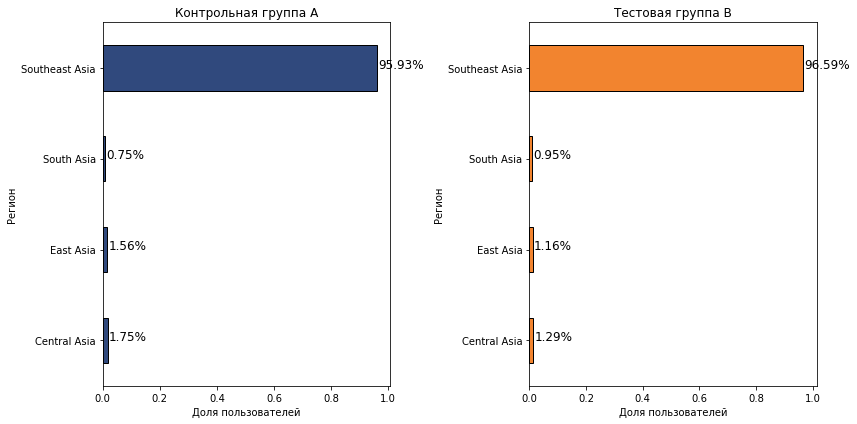

In [21]:
# Построим диаграммы с долей пользователей по регионам в обеих группах

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))  

regions_a.plot(
    kind = 'barh',
    rot = 0,
    legend = False,
    color = '#30497D',
    edgecolor = 'k',
    ax = ax1
)

for p in ax1.patches:
    width = p.get_width()
    ax1.text(
        width+ 0.005,
        p.get_y() + p.get_height() / 2., 
        f'{width:.2%}',       
        fontsize=12
    )

ax1.set_xlabel('Доля пользователей')
ax1.set_ylabel('Регион')
ax1.set_title('Контрольная группа А')

regions_b.plot(
    kind = 'barh',
    rot = 0,
    legend = False,
    color = '#F2842F',
    edgecolor = 'k',
    ax = ax2
)

for p in ax2.patches:
    width = p.get_width()
    ax2.text(
        width+ 0.005,
        p.get_y() + p.get_height() / 2., 
        f'{width:.2%}', 
        fontsize=12
    )

ax2.set_xlabel('Доля пользователей')
ax2.set_ylabel('Регион')
ax2.set_title('Тестовая группа В')

plt.tight_layout()
plt.show()

Видим, что распределение по регионам также равномерное. 

**Вывод**

По результатам анализа корректности сбора данных можно сделать следующие выводы: 
- Количество пользователей в каждой группе исследования составляет примерно 1/2 от всех пользователей, участвующих в исследовании (отклонение 2.1%). Это позволяет продолжить тестрование; 
- Пересечение пользователей из тестовой и контрольной групп не было обнаружено. Это говорит о том, что выборки являются независимыми;
- Сохраняется равномерное распределение пользователей тестовой и контрольной групп по устройствам и регионам.

Таким образом, А/В тест прошел корректно, поэтому можем проводить дальнейший анализ данных и проверять, поставленную бизнесом гипотезу.
___

## 2. Исследовательский анализ данных

Построим графики кумулятивной динамики покупок и конверсий в покупки, чтобы наглядно увидеть эффект от теста в обеих группах. 

In [22]:
# Объединим данные из датасета с сессиями пользователей с датасетом разделения их на группы
sessions_participants_test = sessions_test.merge(participants_test, on = 'user_id')
sessions_participants_test

,user_id,session_start,session_duration,group,ab_test
0,8942E64218C9A1ED,2025-06-01,3.54,B,new_payment_funnel_test_summer_2025
1,8942E64218C9A1ED,2025-06-02,7.54,B,new_payment_funnel_test_summer_2025
2,8942E64218C9A1ED,2025-06-04,3.54,B,new_payment_funnel_test_summer_2025
3,8942E64218C9A1ED,2025-06-08,2.54,B,new_payment_funnel_test_summer_2025
4,8942E64218C9A1ED,2025-06-10,6.54,B,new_payment_funnel_test_summer_2025
...,...,...,...,...,...
11316,B1AE8A7BF57F5B5D,2025-06-16,5.00,A,new_payment_funnel_test_summer_2025
11317,B1AE8A7BF57F5B5D,2025-06-17,2.00,A,new_payment_funnel_test_summer_2025
11318,272ACAAB1FD9F964,2025-06-14,3.00,B,new_payment_funnel_test_summer_2025
11319,272ACAAB1FD9F964,2025-06-15,2.00,B,new_payment_funnel_test_summer_2025


In [23]:
# Посчитаем количество сессий в каждой группе по дням 
# Проведём сортировку по возрастанию даты 
count_sessions = (
    sessions_participants_test
    .groupby(['session_start','group'])
    .size()
    .reset_index(name='count_sessions')
    .sort_values(by='session_start')
)

In [24]:
# Посчитаем кумулятивное количество сессий за весь период эксперимента по группам
count_sessions['cum_sessions'] = count_sessions.groupby('group')['count_sessions'].cumsum()
count_sessions.head()

,session_start,group,count_sessions,cum_sessions
0,2025-06-01,A,166,166
1,2025-06-01,B,161,161
2,2025-06-02,A,192,358
3,2025-06-02,B,178,339
4,2025-06-03,A,194,552


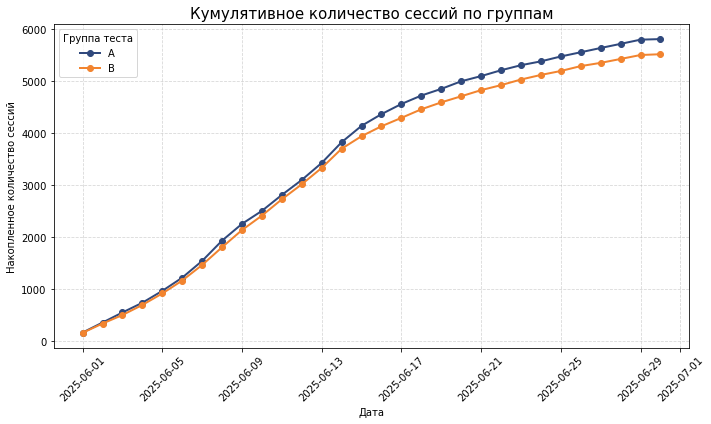

In [25]:
# Отобразим на графике изменение количества сессий по группам за исследуемый период
sessions_pivot = count_sessions.pivot(index = 'session_start',
                                      columns = 'group',
                                      values = 'cum_sessions')

ax = sessions_pivot.plot(
    kind = 'line',
    color = ['#30497D','#F2842F'],
    marker = 'o',
    figsize = (10,6),
    linewidth = 2
)

ax.set_title('Кумулятивное количество сессий по группам', fontsize = 15)
ax.set_xlabel('Дата')
ax.set_ylabel('Накопленное количество сессий')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(title='Группа теста')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

На графике видим небольшое отклонение в большую сторону сессий пользователей в группе А. Однако, разница не кажется критичной между группами. Посмотрим на динамику покупок в этих двух группах.

In [26]:
# Объединим данные из датасета с покупками и разделением их на группы
purchases_participants_test = purchases_test.merge(participants_test, on = 'user_id')

In [27]:
# Посчитаем количество покупок за каждый день в обеих группах
count_purchases = purchases_participants_test.groupby(['event_dt','group']).size().reset_index(name='count')

In [28]:
# Посчитаем кумулятивную сумму покупок за весь период эксперимента
cum_purchases = count_purchases.sort_values(by='event_dt').assign(cumulative_count=lambda x: x.groupby('group')['count'].cumsum())
cum_purchases.head()

,event_dt,group,count,cumulative_count
0,2025-06-01,A,44,44
1,2025-06-01,B,48,48
2,2025-06-02,A,49,93
3,2025-06-02,B,46,94
4,2025-06-03,A,38,131


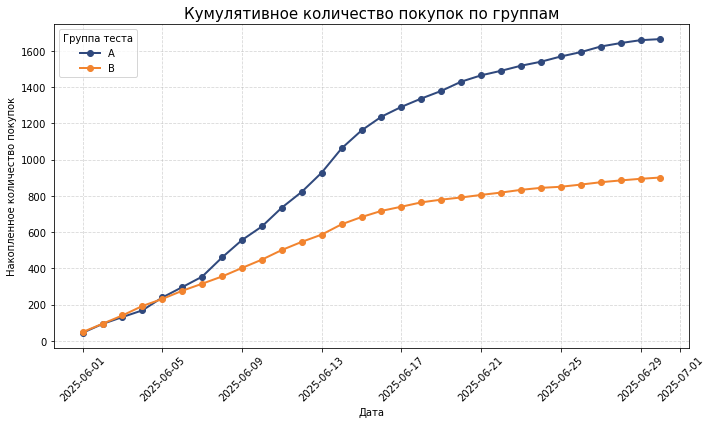

In [29]:
#Отобразим на графике изменение количества покупок по группам

cum_purchases_pivot = cum_purchases.pivot(index = 'event_dt',
                                          columns = 'group',
                                          values = 'cumulative_count')
ax = cum_purchases_pivot.plot( 
    kind = 'line',
    marker = 'o',
    figsize = (10,6),
    linewidth = 2,
    color = ['#30497D','#F2842F']
    )
ax.set_title('Кумулятивное количество покупок по группам', fontsize = 15)
ax.set_xlabel('Дата')
ax.set_ylabel('Накопленное количество покупок')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(title='Группа теста')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

Таким образом, на обоих графиках мы видим преобладание группы А над группой B. У пользователей из этой группы было больше сессий и большее количество покупок. 
Кумулятивная динамика покупок в итоге отличается в 2 раза между контрольной и тестовой группами ( в пользу 1). 

Посмотрим на конверсии из регистрации в покупку в обеих группах. 

In [30]:
#Рассчитаем количество регистраций в обеих группах 
new_users_sum = new_participants_test.groupby('group')['user_id'].nunique()

In [31]:
# Рассчитаем общее количество пользоваетелей, совершивших покупку
purchases_sum = purchases_participants_test.groupby('group')['user_id'].nunique()
purchases_sum

group
A    472
B    270
Name: user_id, dtype: int64

In [32]:
# Рассчитаем конверсию из регистрацию в покупку
conversion = round(purchases_sum / new_users_sum,2)
conversion

group
A    0.30
B    0.18
Name: user_id, dtype: float64

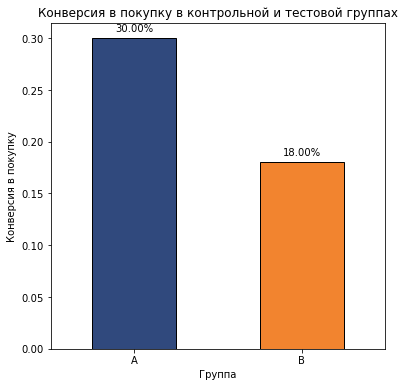

In [33]:
# Построим график конверсий регистрации в покупку в обеих группах

ax = conversion.plot(
    kind = 'bar',
    legend = False,
    color = ['#30497D','#F2842F'],
    edgecolor = 'k',
    rot = 0,
    figsize = (6,6)
)

for p in ax.patches:
    height = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2., 
        height + 0.005, 
        f'{height:.2%}',  
        ha='center',      
        va='bottom',       
        fontsize=10
    )
plt.xlabel('Группа')
plt.ylabel('Конверсия в покупку')
plt.title('Конверсия в покупку в контрольной и тестовой группах',fontsize = 12)
plt.show()

Мы видим, что конверсия из регистрации в покупку намного выше в группе А, то есть до обновлений и введения новой платёжной воронки. Чтобы убедиться в значимости полученных нами результатов, проведём статистический тест. 
___

## 3. Проверка гипотез

Мы исследуем конверсию, поэтому для определения статистической значимости ипсользуем z-test пропорций, так как он подходит для долевых, независимых метрик. 

In [34]:
# Выведем размер групп 
n_a = count_a
n_b = count_b

# Выведем количество успехов (пользователей, совершивших покупку) в каждой группе 
m_a = purchases_sum.loc['A']
m_b = purchases_sum.loc['B']

# Выведем доли успехов для каждой группы 
p_a, p_b = m_a/n_a, m_b/n_b

# Проверим предпосылку о достаточном количестве данных 
if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10): 
    print('Предпосылка о достаточном количестве данных выполняется.')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется.')

# Установим уровень значимости

alpha = 0.05 

# Проведём z-тест пропорций 

stat_ztest, p_value_ztest = proportions_ztest(
    [m_a,m_b],
    [n_a,n_b],
    alternative='larger'
)

print(f'pvalue={p_value_ztest:.4f}')


if p_value_ztest > alpha:
    print('Нулевая гипотеза находит подтверждение.')
    text_interpretation = 'не изменилась'
else:
    print('Нулевая гипотеза не находит подтверждения.')
    text_interpretation = 'снизилась' 

print(f'При внедрении новой платёжной воронки в интернет-магазин конверсия в покупку {text_interpretation}.')

Предпосылка о достаточном количестве данных выполняется.
pvalue=0.0000
Нулевая гипотеза не находит подтверждения.
При внедрении новой платёжной воронки в интернет-магазин конверсия в покупку снизилась.


## 4. Формулирование выводов и рекомендаций

В этом проекте были проанализированы результаты проведённого А/В теста для определения эффективности новой версии платёжной воронки интернет-магазина. 

- Характеристики эксперимента: 
    - Цель - увеличить конверсию из регистрации в онлайн-магазине в покупку. Эксперимет проводился по схеме А/В теста, пользователи случайным образом были распределены на контрольную и тестовую группы. Тест проведён в соответствии с техническим заданием; 
    - Распределение на тестовые группы было корректным. Наблюдается небольшое расхождение в количестве участников в группах, однако, это не оказывает влияение на результаты эксперимента, так как доли групп А и В  составляют 52,1% и 47,9% соответственно. По регионам и устройствам распределение было также корректным; 
    - По результатам теста мы видим, что в тестовой группе наша целевая метрика - конверсия в покупку, снизилась на 12 процентных пунктов (с 30% в контрольной группе до 18% в тестовой). Это соответствует относительному падению на 40%. Разница статистически значима (p-value < 0.05), что подтверждает: снижение вызвано внедрением новой версии воронки, а не случайной погрешностью выборки.
    
- Рекомендации: 
    - Откатить изменения. Новая версия платёжной воронки оказала негативный эффект на целевой показатель, учитывая масштаб падения конверсии, внедрение приведёт к потерям выручки;
    - Провести техническую диагностику, так как существенное падение метрики вероятнее всего связано с критическими техническими сбоями. Необходимо проанализировать логи ошибок, также сгруппировав их по группам А и В. 